# 01 · Datos y limpieza

Carga del dataset crudo del programa de viajero frecuente, diagnóstico de calidad y aplicación de
las reglas de limpieza del proyecto.

- **Entrada:** `data/raw/flight.csv` (descargar con `uv run poe download`).
- **Salida:** `data/interim/flight_clean.parquet` + `cleaning_lineage.json` (los genera
  `uv run poe clean`; este notebook reproduce el proceso paso a paso).
- La lógica vive en `src/segmentacion/` (probada con tests); el notebook solo la invoca y
  explica los resultados. Versión web: página **Datos** del sitio Quarto.

In [1]:
import pandas as pd

from segmentacion.config import get_config
from segmentacion.data.clean import clean, lineage_report, null_summary
from segmentacion.data.load import load_raw
from segmentacion.data.schema import clean_schema, raw_schema
from segmentacion.viz import eda_charts as ec
from segmentacion.viz.notebook import enable_notebook_renderer

enable_notebook_renderer()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
config = get_config()

## 1. Carga del CSV crudo

`flight.csv` es la concatenación de `flight_train.csv` y `flight_test.csv` de la competición de
Kaggle: el *test* solo contiene socios con 2–10 vuelos, así que usar solo el *train* sesgaría la
segmentación.

In [2]:
raw = load_raw(config.raw_file)
print(f"{len(raw):,} socios × {raw.shape[1]} columnas")
raw.head()

62,988 socios × 23 columnas


,MEMBER_NO,FFP_DATE,FIRST_FLIGHT_DATE,GENDER,FFP_TIER,WORK_CITY,WORK_PROVINCE,WORK_COUNTRY,AGE,LOAD_TIME,FLIGHT_COUNT,BP_SUM,SUM_YR_1,SUM_YR_2,SEG_KM_SUM,LAST_FLIGHT_DATE,LAST_TO_END,AVG_INTERVAL,MAX_INTERVAL,EXCHANGE_COUNT,avg_discount,Points_Sum,Point_NotFlight
0,54993,11/2/2006,12/24/2008,Male,6,.,beijing,CN,31.00,3/31/2014,210,505308,"239,560.00","234,188.00",580717,3/31/2014,1,3.48,18,34,0.96,619760,50
1,28065,2/19/2007,8/3/2007,Male,6,NaN,beijing,CN,42.00,3/31/2014,140,362480,"171,483.00","167,434.00",293678,3/25/2014,7,5.19,17,29,1.25,415768,33
2,55106,2/1/2007,8/30/2007,Male,6,.,beijing,CN,40.00,3/31/2014,135,351159,"163,618.00","164,982.00",283712,3/21/2014,11,5.30,18,20,1.25,406361,26
3,21189,8/22/2008,8/23/2008,Male,5,Los Angeles,CA,US,64.00,3/31/2014,23,337314,"116,350.00","125,500.00",281336,12/26/2013,97,27.86,73,11,1.09,372204,12
4,39546,4/10/2009,4/15/2009,Male,6,guiyang,guizhou,CN,48.00,3/31/2014,152,273844,"124,560.00","130,702.00",309928,3/27/2014,5,4.79,47,27,0.97,338813,39


In [3]:
raw.dtypes.to_frame("dtype").T

,MEMBER_NO,FFP_DATE,FIRST_FLIGHT_DATE,GENDER,FFP_TIER,WORK_CITY,WORK_PROVINCE,WORK_COUNTRY,AGE,LOAD_TIME,FLIGHT_COUNT,BP_SUM,SUM_YR_1,SUM_YR_2,SEG_KM_SUM,LAST_FLIGHT_DATE,LAST_TO_END,AVG_INTERVAL,MAX_INTERVAL,EXCHANGE_COUNT,avg_discount,Points_Sum,Point_NotFlight
dtype,int64,str,str,str,int64,str,str,str,float64,str,int64,int64,float64,float64,int64,str,int64,float64,int64,int64,float64,int64,int64


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
MEMBER_NO,"62,988.00","31,494.50","18,183.21",1.00,"15,747.75","31,494.50","47,241.25","62,988.00"
FFP_TIER,"62,988.00",4.10,0.37,4.00,4.00,4.00,4.00,6.00
AGE,"62,568.00",42.48,9.89,6.00,35.00,41.00,48.00,110.00
FLIGHT_COUNT,"62,988.00",11.84,14.05,2.00,3.00,7.00,15.00,213.00
BP_SUM,"62,988.00","10,925.08","16,339.49",0.00,"2,518.00","5,700.00","12,831.00","505,308.00"
SUM_YR_1,"62,437.00","5,355.38","8,109.45",0.00,"1,003.00","2,800.00","6,574.00","239,560.00"
SUM_YR_2,"62,850.00","5,604.03","8,703.36",0.00,780.00,"2,773.00","6,845.75","234,188.00"
SEG_KM_SUM,"62,988.00","17,123.88","20,960.84",368.00,"4,747.00","9,994.00","21,271.25","580,717.00"
LAST_TO_END,"62,988.00",176.12,183.82,1.00,29.00,108.00,268.00,731.00
AVG_INTERVAL,"62,988.00",67.75,77.52,0.00,23.37,44.67,82.00,728.00


## 2. Diagnóstico de calidad

### 2.1 Nulos explícitos

In [5]:
nulls = raw.isna().sum()
nulls[nulls > 0].sort_values(ascending=False).to_frame("nulos").assign(
    pct=lambda d: d["nulos"] / len(raw)
)

,nulos,pct
WORK_PROVINCE,3248,0.05
WORK_CITY,2269,0.04
SUM_YR_1,551,0.01
AGE,420,0.01
SUM_YR_2,138,0.00
WORK_COUNTRY,26,0.00
GENDER,3,0.00


### 2.2 Nulos disfrazados (*placeholders*) en la ubicación

Valores como `.`, `-` o `0` significan «sin dato», pero pandas los lee como texto válido.

In [6]:
placeholders = list(config.cleaning.text_placeholders)
for column in ["WORK_CITY", "WORK_PROVINCE"]:
    values = raw[column].astype("str").str.strip()
    print(column, values[values.isin(placeholders)].value_counts().to_dict())

WORK_CITY {'.': 667, '-': 79, '。': 15, '0': 4, '`': 2}
WORK_PROVINCE {'.': 930, '-': 262, '`': 20, '0': 14, '。': 12, '——': 1}


### 2.3 Variantes de una misma provincia o ciudad

El texto mezcla mayúsculas, caracteres de ancho completo y sufijos administrativos en pinyin
(`sheng` = provincia, `shi` = ciudad): `guangdongsheng` y `Guangdong` son la misma provincia.

In [7]:
province = raw["WORK_PROVINCE"].dropna().astype("str").str.strip().str.lower()
province[province.str.contains("guangdong")].value_counts().head(8)

WORK_PROVINCE
guangdong                        17524
guangdongsheng                     815
guangdong.                           3
guangdongshi                         1
guangdongzengcheng                   1
zhongguo guangdongsheng              1
guangdongsheng`                      1
jilinsheng,huo:guangdongsheng        1
Name: count, dtype: int64

In [8]:
province[~province.str.isascii()].value_counts().head(8)

WORK_PROVINCE
。                   12
－                    7
beijing、xinjiang     1
shanxian            1
hubei、               1
ｔｗ                   1
．                    1
briarcliff　manol     1
Name: count, dtype: int64

### 2.4 Fechas imposibles

- `LAST_FLIGHT_DATE = 2014/2/29` no existe (2014 no es bisiesto).
- `FIRST_FLIGHT_DATE` tiene valores de 1905 y posteriores a la fecha de corte.

In [9]:
date_format = config.cleaning.date_format
print("LAST_FLIGHT_DATE = 2014/2/29:", (raw["LAST_FLIGHT_DATE"] == "2014/2/29").sum())
first = pd.to_datetime(raw["FIRST_FLIGHT_DATE"], format=date_format, errors="coerce")
load = pd.to_datetime(raw["LOAD_TIME"], format=date_format)
print("FIRST_FLIGHT_DATE fuera de ventana:", ((first > load) | (first.dt.year < 2000)).sum())
print("LOAD_TIME únicos:", raw["LOAD_TIME"].unique())

LAST_FLIGHT_DATE = 2014/2/29: 0


FIRST_FLIGHT_DATE fuera de ventana: 8
LOAD_TIME únicos: <ArrowStringArray>
['3/31/2014']
Length: 1, dtype: str


### 2.5 Ingresos y edad

Sin ingresos no se puede validar el valor del cliente; y un ingreso 0 con km volados indica viajes
pagados íntegramente con puntos (canjes).

In [10]:
revenue_null = raw["SUM_YR_1"].isna() | raw["SUM_YR_2"].isna()
redemption = (raw["SUM_YR_1"] + raw["SUM_YR_2"] == 0) & (raw["SEG_KM_SUM"] > 0)
print(f"Ingreso nulo: {revenue_null.sum():,} · Ingreso 0 con vuelos: {redemption.sum():,}")
print("Edad fuera de [18, 100]:", (~raw["AGE"].between(18, 100) & raw["AGE"].notna()).sum())

Ingreso nulo: 689 · Ingreso 0 con vuelos: 255
Edad fuera de [18, 100]: 52


In [11]:
raw_schema().validate(raw)
print("El CSV crudo cumple el esquema mínimo (columnas, MEMBER_NO único, rangos ≥ 0).")

El CSV crudo cumple el esquema mínimo (columnas, MEMBER_NO único, rangos ≥ 0).


## 3. Limpieza

Criterio: **solo se elimina un socio si su fila no sirve para calcular LRFMC**. Si el problema
está en una columna de perfil (ubicación, edad, fechas que no entran al modelo), se anula ese
valor y el socio se conserva. Cada regla registra cuántas filas toca (*data lineage*).

In [12]:
df, lineage = clean(raw, config.cleaning)
report = lineage_report(len(raw), len(df), lineage)
report["null_counts"] = null_summary(raw, df)
retained = report["output_rows"] / report["input_rows"]
print(f"{report['input_rows']:,} → {report['output_rows']:,} socios ({retained:.1%} retenido)")
ec.lineage_table(report)

62,988 → 62,044 socios (98.5% retenido)


,Regla,Acción,Filas,% del crudo
0,WORK_CITY sin dato real → nulo,Anula el valor,796,0.01
1,WORK_PROVINCE sin dato real → nulo,Anula el valor,1267,0.02
2,WORK_COUNTRY no es un código ISO-2 → nulo,Anula el valor,14,0.00
3,LAST_FLIGHT_DATE inexistente → nulo,Anula el valor,421,0.01
4,FIRST_FLIGHT_DATE anterior al alta o posterior...,Anula el valor,8,0.00
5,SUM_YR_1 o SUM_YR_2 nulo,Elimina el socio,689,0.01
6,Ingreso total 0 con km volados (vuelos de canj...,Elimina el socio,255,0.00
7,"AGE fuera de [18, 100] → nulo",Anula el valor,49,0.00


alt.LayerChart(...)
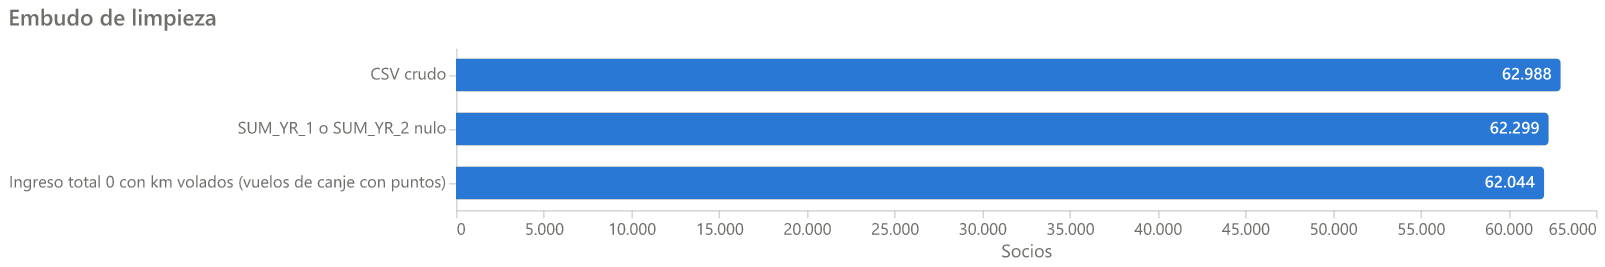

In [13]:
ec.cleaning_funnel_chart(report)

alt.Chart(...)
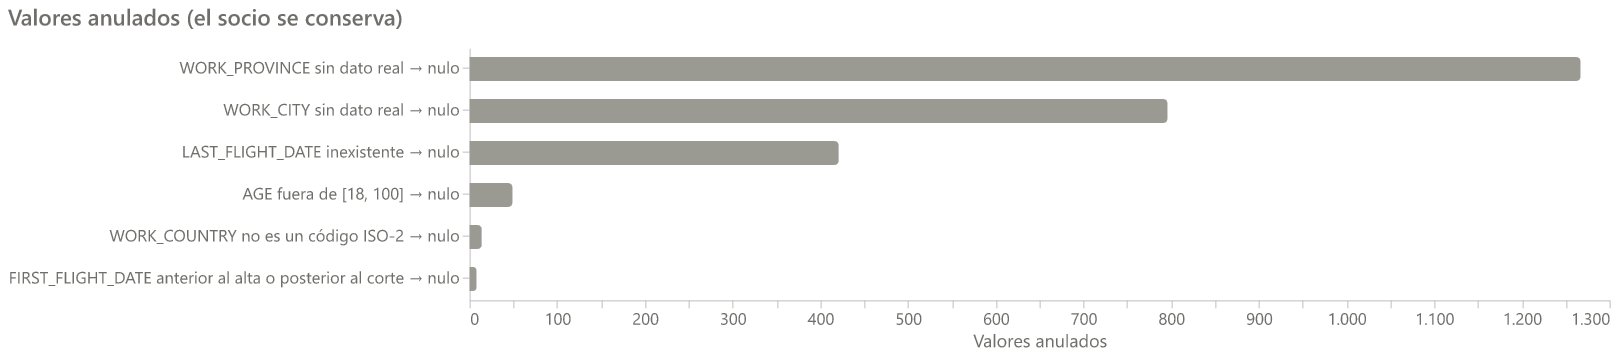

In [14]:
ec.nulled_values_chart(report)

alt.Chart(...)
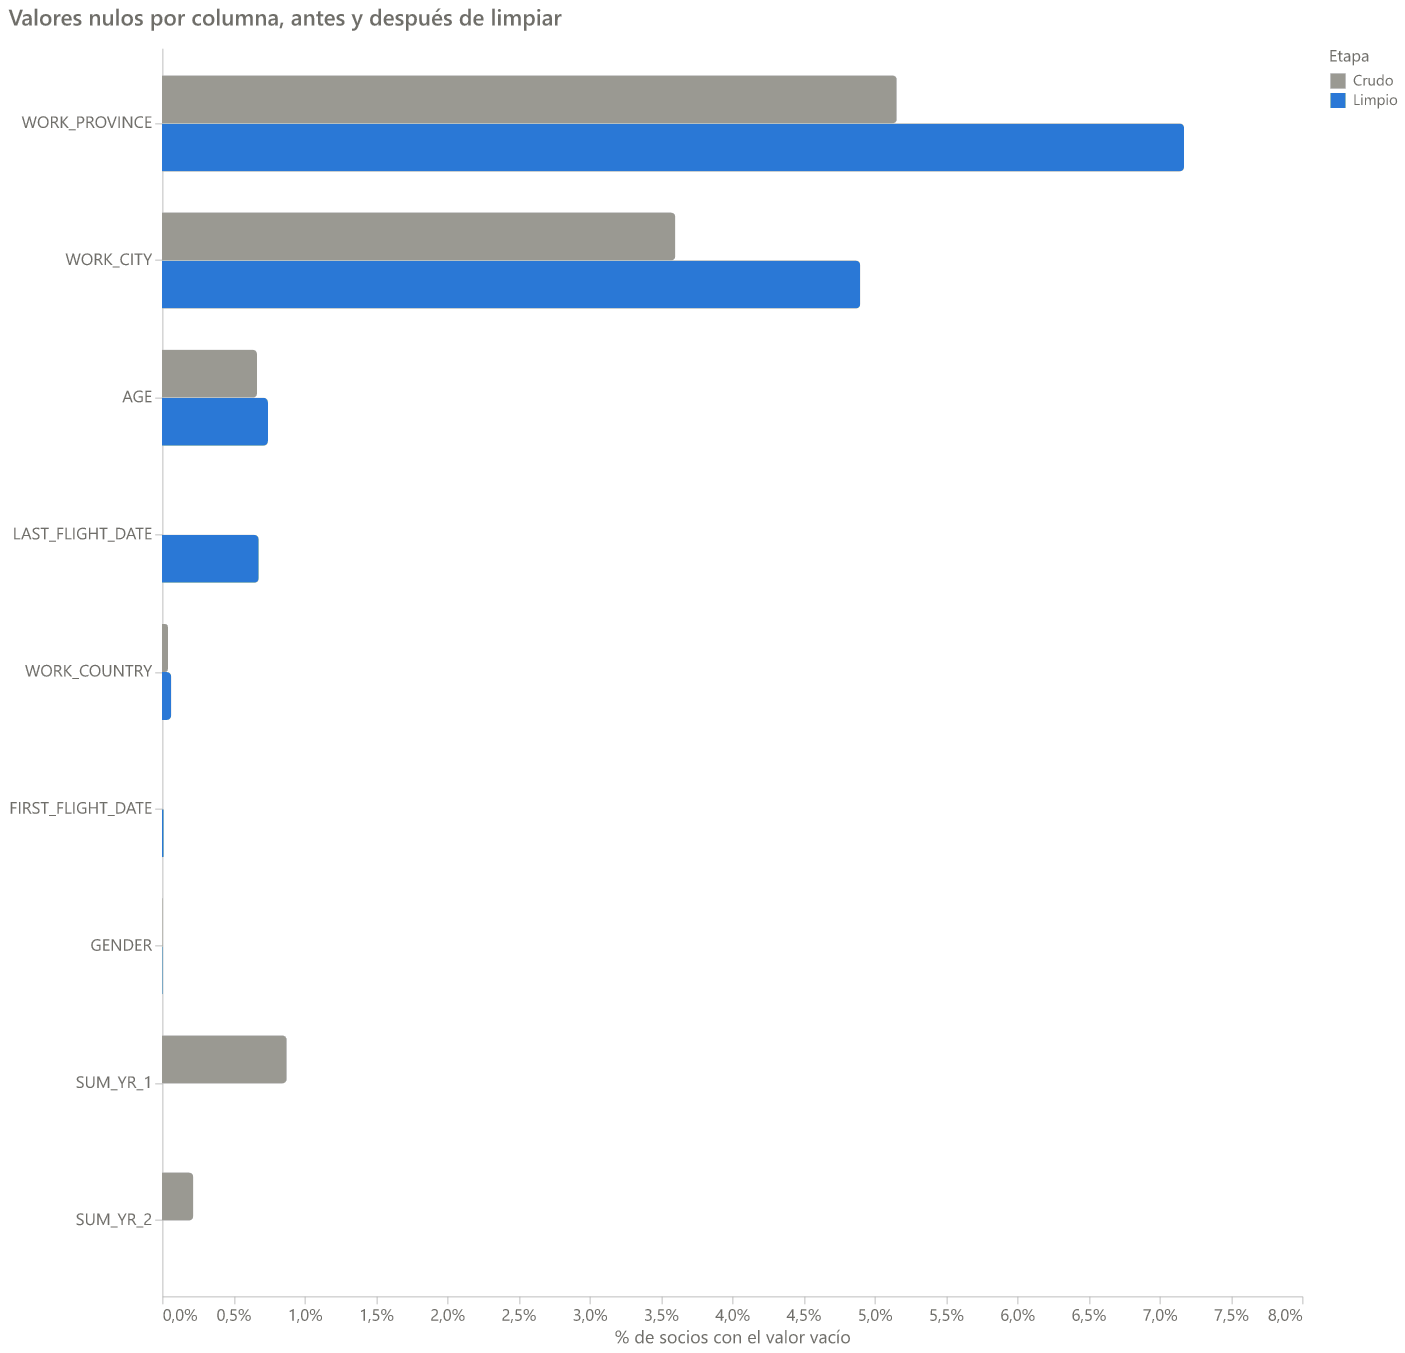

In [15]:
ec.null_values_chart(report)

Tras limpiar hay **más** nulos en ubicación: los *placeholders* pasan a contarse como lo que
son. Las columnas que alimentan LRFMC quedan sin ningún nulo.

In [16]:
lrfmc_sources = ["FFP_DATE", "LOAD_TIME", "FLIGHT_COUNT", "SEG_KM_SUM", "LAST_TO_END"]
df[[*lrfmc_sources, "avg_discount"]].isna().sum().to_frame("nulos").T

,FFP_DATE,LOAD_TIME,FLIGHT_COUNT,SEG_KM_SUM,LAST_TO_END,avg_discount
nulos,0,0,0,0,0,0


In [17]:
df["WORK_PROVINCE"].value_counts().head(10).to_frame("socios")

,socios
WORK_PROVINCE,
guangdong,18264
beijing,8104
liaoning,4937
shanghai,4842
xinjiang,2401
jilin,2314
hubei,1522
heilongjiang,1487
henan,1267


In [18]:
clean_schema(config.cleaning).validate(df)
print("El dataset limpio cumple el contrato (tipos, reglas de negocio, sin placeholders).")

El dataset limpio cumple el contrato (tipos, reglas de negocio, sin placeholders).


## 4. Conclusiones

- Se conservan **62.044 socios (98,5 %)**; solo se eliminan 689 con ingresos nulos y 255 con
  ingreso 0 que sí volaron (canjes).
- 421 `LAST_FLIGHT_DATE` inexistentes y 8 `FIRST_FLIGHT_DATE` imposibles se anulan sin perder al
  socio: R se calcula con `LAST_TO_END`, que es válido.
- La ubicación se normaliza (NFKC, minúsculas, sufijos pinyin) para que el perfilado regional no
  cuente dos veces la misma provincia.
- Siguiente paso: [02 · EDA](02_eda.ipynb).